In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

In [30]:
df = sns.load_dataset("titanic")

In [31]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [32]:
df[["sex", "class", "embark_town"]].isnull().sum()

sex            0
class          0
embark_town    2
dtype: int64

In [33]:
df = df.dropna(subset=["embark_town"])

In [34]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [35]:
df[["sex", "class", "embark_town"]].isnull().sum()

sex            0
class          0
embark_town    0
dtype: int64

In [36]:
df["sex"].value_counts()

sex
male      577
female    312
Name: count, dtype: int64

In [37]:
df["embark_town"].value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [38]:
df["class"].value_counts()

class
Third     491
First     214
Second    184
Name: count, dtype: int64

In [39]:
df_onehot = pd.get_dummies(data=df, columns=["sex", "embark_town"], drop_first=True)

In [40]:
df_onehot

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,alive,alone,sex_male,embark_town_Queenstown,embark_town_Southampton
0,0,3,22.0,1,0,7.2500,S,Third,man,True,NaN,no,False,True,False,True
1,1,1,38.0,1,0,71.2833,C,First,woman,False,C,yes,False,False,False,False
2,1,3,26.0,0,0,7.9250,S,Third,woman,False,NaN,yes,True,False,False,True
3,1,1,35.0,1,0,53.1000,S,First,woman,False,C,yes,False,False,False,True
4,0,3,35.0,0,0,8.0500,S,Third,man,True,NaN,no,True,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,S,Second,man,True,NaN,no,True,True,False,True
887,1,1,19.0,0,0,30.0000,S,First,woman,False,B,yes,True,False,False,True
888,0,3,NaN,1,2,23.4500,S,Third,woman,False,NaN,no,False,False,False,True
889,1,1,26.0,0,0,30.0000,C,First,man,True,C,yes,True,True,False,False


In [41]:
df_onehot.columns

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'embarked',
       'class', 'who', 'adult_male', 'deck', 'alive', 'alone', 'sex_male',
       'embark_town_Queenstown', 'embark_town_Southampton'],
      dtype='object')

In [42]:
# get_dummies metoduyla yapınca kategorik değişken sayısı - 1 tane kolon dönüyor. 3 Kategorik değişken için 2 tanesinin değerini biliyorsak 3.'yü kesin olarak bilebiliriz. Serbestlik derecesi kavramının öne çıktığı bir durum.

In [43]:
# label encoder

In [44]:
label_encoder = LabelEncoder()

In [45]:
df_label = df.copy()

In [46]:
df_label["sex"] = label_encoder.fit_transform(df_label["sex"])

In [47]:
df_label

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,0,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,0,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,1,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [64]:
# ordinal encoder

In [80]:
df_ordinal = df.copy()

In [81]:
class_order = ["Third", "Second", "First"]

In [82]:
ordinal_encoder = OrdinalEncoder()

In [83]:
df_ordinal["class"] = ordinal_encoder.fit_transform(df_ordinal[["class"]])

In [84]:
df_ordinal

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,2.0,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,0.0,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,2.0,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,0.0,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,2.0,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,1.0,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,0.0,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,2.0,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,0.0,man,True,C,Cherbourg,yes,True


<Axes: title={'center': 'OneHot Encoded'}, xlabel='sex_male'>

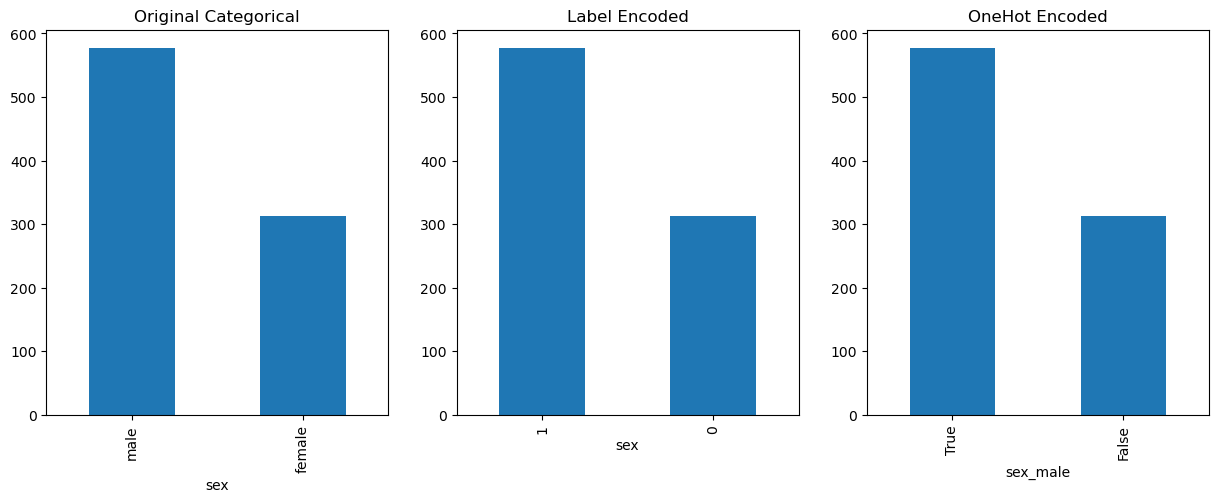

In [113]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
df["sex"].value_counts().plot(kind="bar",ax=axes[0], title="Original Categorical")
df_label["sex"].value_counts().plot(kind="bar", ax=axes[1], title="Label Encoded")
df_onehot["sex_male"]. value_counts().plot(kind="bar", ax=axes[2], title="OneHot Encoded")

In [100]:
df_grouped = df.groupby("class")

C:\Users\merty\AppData\Local\Temp\ipykernel_18636\32566947.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df.groupby("class")


In [102]:
df_grouped["fare"].mean()

class
First     84.193516
Second    20.662183
Third     13.675550
Name: fare, dtype: float64

C:\Users\merty\AppData\Local\Temp\ipykernel_18636\732882134.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="class", y="fare", palette=["b", "g", "r"])


<Axes: xlabel='class', ylabel='fare'>

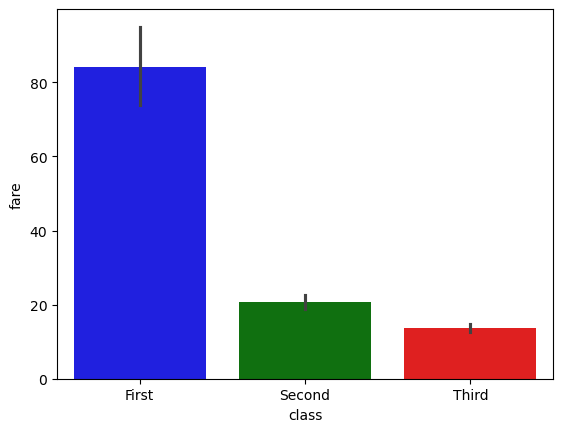

In [111]:
sns.barplot(data=df, x="class", y="fare", palette=["b", "g", "r"])